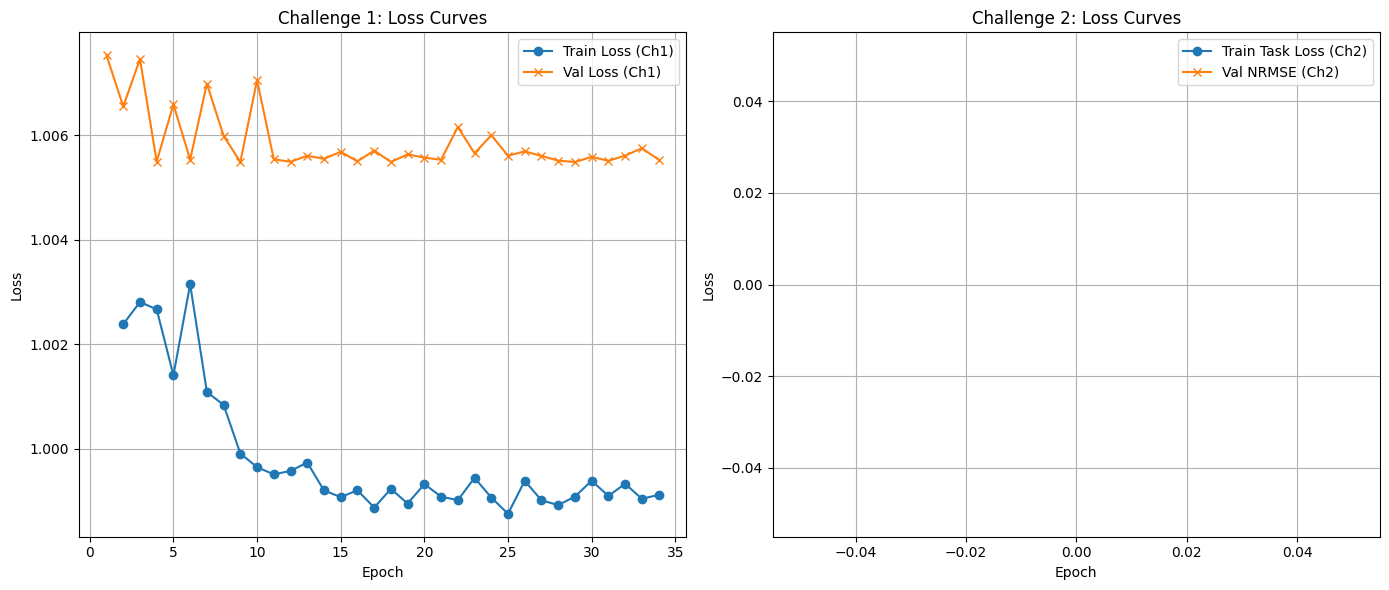

✅ Plot saved as training_curves_both_challenges.png


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# ----------- File Paths -----------
csv_ch1 = "results_challenge1.csv"     # ensure this path matches your setup
csv_ch2 = "results_challenge2.csv"     # ensure this path matches your setup

# ----------- Read CSVs -----------
df_ch1 = pd.read_csv(csv_ch1)
df_ch2 = pd.read_csv(csv_ch2)

# ----------- Plotting -----------
plt.figure(figsize=(14, 6))

# ----------- Challenge 1: Train Loss and Val Loss ----------- #
plt.subplot(1, 2, 1)
plt.plot(df_ch1["epoch"][1:], df_ch1["train_loss"][1:], label="Train Loss (Ch1)", marker='o')
if "val_loss" in df_ch1.columns:
    plt.plot(df_ch1["epoch"], df_ch1["val_loss"], label="Val Loss (Ch1)", marker='x')
elif "val_rmse" in df_ch1.columns:
    plt.plot(df_ch1["epoch"], df_ch1["val_rmse"], label="Val RMSE (Ch1)", marker='x')
plt.title("Challenge 1: Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

# ----------- Challenge 2: Train Loss and Val Loss ----------- #
plt.subplot(1, 2, 2)
plt.plot(df_ch2["epoch"], df_ch2["train_task_loss"], label="Train Task Loss (Ch2)", marker='o')
if "val_nrmse" in df_ch2.columns:
    plt.plot(df_ch2["epoch"], df_ch2["val_nrmse"], label="Val NRMSE (Ch2)", marker='x')
elif "val_rmse" in df_ch2.columns:
    plt.plot(df_ch2["epoch"], df_ch2["val_rmse"], label="Val RMSE (Ch2)", marker='x')
plt.title("Challenge 2: Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

# ----------- Save and Show ----------- #
plt.tight_layout()
plt.savefig("training_curves_both_challenges.png", dpi=300)
plt.show()

print("✅ Plot saved as training_curves_both_challenges.png")


In [2]:
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

from dataloader import EEGChallengeDataLoader
from models import EEGFeatureExtractor, EEG_CCD_Model, EEG_Externalizing_Model  # Challenge 2
from config import DEVICE

# ---------------------- CONFIG ---------------------- #
CHECKPOINT_PATH = r"E:\EEG_Challenge2025_neurips\checkpoints\submitted_24_oct_v1\best_challenge1.pt"  # ✅ Use RMSE-trained model
BATCH_SIZE = 512
R_SETS = ["R1", "R2", "R3", "R4", "R5", "R6"]  # Reference datasets
IS_CHALLENGE_1 = True  # Set False if loading challenge 2 model

# ------------------ LOAD MODEL ---------------------- #
backbone = EEGFeatureExtractor(channels=129, time_steps=200)

if IS_CHALLENGE_1:
    model = EEG_CCD_Model(backbone)
else:
    model = EEG_Externalizing_Model(backbone, num_subjects=50)  # Update subject count if needed

model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE))
model.to(DEVICE)
model.eval()
print(model)
print(f"✅ Loaded model from {CHECKPOINT_PATH}")

# ----------------- EVALUATION LOOP ------------------ #
loader = EEGChallengeDataLoader()
rmse_results = {}

with torch.no_grad():
    for r_set in R_SETS:
        r_number = int(r_set[1:])  # Convert "R3" → 3
        print(f"\n🔍 Evaluating on  (Release {r_set})...")

        # Load reference dataset for this R-set
        train_loader, _, _ = loader.load_reference(challenge=1 if IS_CHALLENGE_1 else 2, release=[r_set])

        preds, targets = [], []

        for X, y, *_ in train_loader:
            X = X.to(DEVICE, dtype=torch.float32)
            y = y.to(DEVICE, dtype=torch.float32).view(-1)

            if IS_CHALLENGE_1:
                y_pred = model(X).view(-1)
            else:
                y_pred, _ = model(X, lambd=0.0)
                y_pred = y_pred.view(-1)

            preds.append(y_pred.cpu())
            targets.append(y.cpu())

        preds, targets = torch.cat(preds), torch.cat(targets)
        
        # ✅ Compute RMSE
        rmse = torch.sqrt(F.mse_loss(preds, targets)).item()
        rmse_results[r_set] = rmse
        print(f"📏 RMSE for {r_set}: {rmse:.4f}")

# ------------------ SUMMARY ------------------ #
print("\n📊 RMSE Summary for All Reference Sets:")
for r_set, rmse in rmse_results.items():
    print(f" - {r_set}: {rmse:.4f}")

avg_rmse = sum(rmse_results.values()) / len(rmse_results)
print(f"\n🏁 Average RMSE across R1–R6: {avg_rmse:.4f}")


CUDA-enabled GPU detected. Using GPU for training.


C:\Users\Prakash\AppData\Local\Temp\ipykernel_33516\1622742908.py:23: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(CHECKPOINT_PATH, map_loc

EEG_CCD_Model(
  (backbone): EEGFeatureExtractor(
    (pre): EEGPreprocessing()
    (spatial): EEGSpatialTransformer(
      (proj): Linear(in_features=200, out_features=256, bias=True)
      (encoder): TransformerEncoder(
        (layers): ModuleList(
          (0-2): 3 x TransformerEncoderLayer(
            (self_attn): MultiheadAttention(
              (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
            )
            (linear1): Linear(in_features=256, out_features=2048, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
            (linear2): Linear(in_features=2048, out_features=256, bias=True)
            (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
            (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
            (dropout1): Dropout(p=0.1, inplace=False)
            (dropout2): Dropout(p=0.1, inplace=False)
          )
        )
      )
    )
    (temporal): EEGTemporalTransformer

c:\Users\Prakash\anaconda3\envs\eegneuronets\lib\site-packages\eegdash\dataset\dataset.py:126: UserWarning: 

[EEGChallengeDataset] EEG 2025 Competition Data Notice:
-------------------------------------------------------
This object loads the HBN dataset that has been preprocessed for the EEG Challenge:
  - Downsampled from 500Hz to 100Hz
  - Bandpass filtered (0.5–50 Hz)

For full preprocessing details, see:
  https://github.com/eeg2025/downsample-datasets

IMPORTANT: The data accessed via `EEGChallengeDataset` is NOT identical to what you get from `EEGDashDataset` directly.
If you are participating in the competition, always use `EEGChallengeDataset` to ensure consistency with the challenge data.


  warn(


✅ Loaded release R2
📦 Combined 301 datasets for Challenge 1.
✅ Challenge 1 ready: Train=6081, Val=1325, Test=159
📏 RMSE for R2: 0.3992

🔍 Evaluating on  (Release R3)...
🔄 Loading reference dataset for Challenge 1 (Release ['R3'])
📥 Loading Challenge 1 dataset from releases: ['R3']


c:\Users\Prakash\anaconda3\envs\eegneuronets\lib\site-packages\eegdash\dataset\dataset.py:126: UserWarning: 

[EEGChallengeDataset] EEG 2025 Competition Data Notice:
-------------------------------------------------------
This object loads the HBN dataset that has been preprocessed for the EEG Challenge:
  - Downsampled from 500Hz to 100Hz
  - Bandpass filtered (0.5–50 Hz)

For full preprocessing details, see:
  https://github.com/eeg2025/downsample-datasets

IMPORTANT: The data accessed via `EEGChallengeDataset` is NOT identical to what you get from `EEGDashDataset` directly.
If you are participating in the competition, always use `EEGChallengeDataset` to ensure consistency with the challenge data.


  warn(


... (5 outputs left out)

✅ Loaded release R5
📦 Combined 745 datasets for Challenge 1.


✅ Challenge 1 ready: Train=12100, Val=2714, Test=330
📏 RMSE for R5: 0.3937

🔍 Evaluating on  (Release R6)...
🔄 Loading reference dataset for Challenge 1 (Release ['R6'])
📥 Loading Challenge 1 dataset from releases: ['R6']


c:\Users\Prakash\anaconda3\envs\eegneuronets\lib\site-packages\eegdash\dataset\dataset.py:126: UserWarning: 

[EEGChallengeDataset] EEG 2025 Competition Data Notice:
-------------------------------------------------------
This object loads the HBN dataset that has been preprocessed for the EEG Challenge:
  - Downsampled from 500Hz to 100Hz
  - Bandpass filtered (0.5–50 Hz)

For full preprocessing details, see:
  https://github.com/eeg2025/downsample-datasets

IMPORTANT: The data accessed via `EEGChallengeDataset` is NOT identical to what you get from `EEGDashDataset` directly.
If you are participating in the competition, always use `EEGChallengeDataset` to ensure consistency with the challenge data.


  warn(


✅ Loaded release R6
📦 Combined 232 datasets for Challenge 1.
✅ Challenge 1 ready: Train=3770, Val=789, Test=116
📏 RMSE for R6: 0.4324

📊 RMSE Summary for All Reference Sets:
 - R1: 0.3933
 - R2: 0.3992
 - R3: 0.4194
 - R4: 0.4022
 - R5: 0.3937
 - R6: 0.4324

🏁 Average RMSE across R1–R6: 0.4067


In [6]:
print("Challenge 1 RSME ",rmse_results)

Challenge 1 RSME  {'R1': 0.39326080679893494, 'R2': 0.3991645872592926, 'R3': 0.41940534114837646, 'R4': 0.4021700918674469, 'R5': 0.3936906158924103, 'R6': 0.43243923783302307}


In [4]:
int(r_set[1:])

6

"R2".numeric

In [2]:
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

from dataloader import EEGChallengeDataLoader
from models import EEGFeatureExtractor, EEG_CCD_Model, EEG_Externalizing_Model
from config import DEVICE

# ---------------------- CONFIG ---------------------- #
CHECKPOINT_PATH = r"checkpoints\submitted_24_oct_v1\best_challenge2.pt"  # ✅ RMSE-trained model
BATCH_SIZE = 512
R_SETS = ["R1", "R2", "R3", "R4", "R5", "R6"]
IS_CHALLENGE_1 = False  # Set True if testing Challenge 1

# ------------------ LOAD MODEL ---------------------- #
def get_model_challenge_2(checkpoint_path):
    """Return pretrained model for Challenge 2 (adversarial regression)."""

    class Challenge2SubmissionWrapper(torch.nn.Module):
        """Wrap EEG_Externalizing_Model to return only regression output."""
        def __init__(self, base_model):
            super().__init__()
            self.base_model = base_model

        def forward(self, x):
            # Disable GRL during inference
            y_pred, _ = self.base_model(x, lambd=0.0)
            return y_pred.unsqueeze(-1) if y_pred.ndim == 1 else y_pred

    # Build base model
    backbone = EEGFeatureExtractor(channels=129, time_steps=200)
    model_base = EEG_Externalizing_Model(backbone, num_subjects=131).to(DEVICE)

    # Load checkpoint safely (ignore discriminator mismatch)
    state = torch.load(checkpoint_path, map_location=DEVICE)
    missing, unexpected = model_base.load_state_dict(state, strict=False)
    print(f"ℹ️ Missing keys: {len(missing)} | Unexpected keys: {len(unexpected)}")

    model_base.eval()

    # Wrap model to only output regression
    model_wrapped = Challenge2SubmissionWrapper(model_base).to(DEVICE)
    model_wrapped.eval()
    return model_wrapped


# Initialize correct model
if IS_CHALLENGE_1:
    backbone = EEGFeatureExtractor(channels=129, time_steps=200)
    model = EEG_CCD_Model(backbone).to(DEVICE)
else:
    model = get_model_challenge_2(CHECKPOINT_PATH)

print(f"✅ Loaded model from {CHECKPOINT_PATH}")

# ----------------- EVALUATION LOOP ------------------ #
loader = EEGChallengeDataLoader()
rmse_results = {}

with torch.no_grad():
    for r_set in R_SETS:
        r_number = int(r_set[1:])  # "R3" -> 3
        print(f"\n🔍 Evaluating on Release {r_set}...")

        # Load reference dataset
        train_loader, _, _ = loader.load_reference(
            challenge=1 if IS_CHALLENGE_1 else 2,
            release=[r_set]
        )

        preds, targets = [], []

        for X, y, *_ in train_loader:
            X = X.to(DEVICE, dtype=torch.float32)
            y = y.to(DEVICE, dtype=torch.float32).view(-1)

            # For Challenge 1: direct model output
            # For Challenge 2: wrapper already disables GRL
            y_pred = model(X).view(-1)

            preds.append(y_pred.cpu())
            targets.append(y.cpu())

        preds, targets = torch.cat(preds), torch.cat(targets)

        # ✅ Compute RMSE
        rmse = torch.sqrt(F.mse_loss(preds, targets)).item()
        rmse_results[r_set] = rmse
        print(f"📏 RMSE for {r_set}: {rmse:.4f}")

# ------------------ SUMMARY ------------------ #
print("\n📊 RMSE Summary for All Reference Sets:")
for r_set, rmse in rmse_results.items():
    print(f" - {r_set}: {rmse:.4f}")

avg_rmse = sum(rmse_results.values()) / len(rmse_results)
print(f"\n🏁 Average RMSE across R1–R6: {avg_rmse:.4f}")


C:\Users\Prakash\AppData\Local\Temp\ipykernel_35628\2585971254.py:35: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(checkpoint_path, map_location=DEVICE)


ℹ️ Missing keys: 0 | Unexpected keys: 0
✅ Loaded model from checkpoints\submitted_24_oct_v1\best_challenge2.pt

🔍 Evaluating on Release R1...
🔄 Loading reference dataset for Challenge 2 (Release ['R1'])
📥 Loading Challenge 2 dataset from releases: ['R1']
🎯 Including tasks: ['contrastChangeDetection', 'RestingState', 'surroundSupp', 'ThePresent', 'seqLearning6target', 'symbolSearch'], using 25% per task per release
✅ Release=R1, Task=contrastChangeDetection: kept 73/293


c:\Users\Prakash\anaconda3\envs\eegneuronets\lib\site-packages\eegdash\dataset\dataset.py:126: UserWarning: 

[EEGChallengeDataset] EEG 2025 Competition Data Notice:
-------------------------------------------------------
This object loads the HBN dataset that has been preprocessed for the EEG Challenge:
  - Downsampled from 500Hz to 100Hz
  - Bandpass filtered (0.5–50 Hz)

For full preprocessing details, see:
  https://github.com/eeg2025/downsample-datasets

IMPORTANT: The data accessed via `EEGChallengeDataset` is NOT identical to what you get from `EEGDashDataset` directly.
If you are participating in the competition, always use `EEGChallengeDataset` to ensure consistency with the challenge data.


  warn(


✅ Release=R1, Task=RestingState: kept 34/136


c:\Users\Prakash\anaconda3\envs\eegneuronets\lib\site-packages\eegdash\dataset\dataset.py:126: UserWarning: 

[EEGChallengeDataset] EEG 2025 Competition Data Notice:
-------------------------------------------------------
This object loads the HBN dataset that has been preprocessed for the EEG Challenge:
  - Downsampled from 500Hz to 100Hz
  - Bandpass filtered (0.5–50 Hz)

For full preprocessing details, see:
  https://github.com/eeg2025/downsample-datasets

IMPORTANT: The data accessed via `EEGChallengeDataset` is NOT identical to what you get from `EEGDashDataset` directly.
If you are participating in the competition, always use `EEGChallengeDataset` to ensure consistency with the challenge data.


  warn(


✅ Release=R1, Task=surroundSupp: kept 51/207


... (62 outputs left out)

c:\Users\Prakash\anaconda3\envs\eegneuronets\lib\site-packages\eegdash\dataset\dataset.py:126: UserWarning: 

[EEGChallengeDataset] EEG 2025 Competition Data Notice:
-------------------------------------------------------
This object loads the HBN dataset that has been preprocessed for the EEG Challenge:
  - Downsampled from 500Hz to 100Hz
  - Bandpass filtered (0.5–50 Hz)

For full preprocessing details, see:
  https://github.com/eeg2025/downsample-datasets

IMPORTANT: The data accessed via `EEGChallengeDataset` is NOT identical to what you get from `EEGDashDataset` directly.
If you are participating in the competition, always use `EEGChallengeDataset` to ensure consistency with the challenge data.


  warn(


✅ Release=R6, Task=seqLearning6target: kept 10/41


c:\Users\Prakash\anaconda3\envs\eegneuronets\lib\site-packages\eegdash\dataset\dataset.py:126: UserWarning: 

[EEGChallengeDataset] EEG 2025 Competition Data Notice:
-------------------------------------------------------
This object loads the HBN dataset that has been preprocessed for the EEG Challenge:
  - Downsampled from 500Hz to 100Hz
  - Bandpass filtered (0.5–50 Hz)

For full preprocessing details, see:
  https://github.com/eeg2025/downsample-datasets

IMPORTANT: The data accessed via `EEGChallengeDataset` is NOT identical to what you get from `EEGDashDataset` directly.
If you are participating in the competition, always use `EEGChallengeDataset` to ensure consistency with the challenge data.


  warn(


✅ Release=R6, Task=symbolSearch: kept 21/85
📦 Combined 202 total recordings after sampling.
✅ Remaining after filtering: 198
🧠 Created mapping for 96 subjects.
✅ Challenge 2 ready:
   Train: 29309 windows (76 subjects)
   Val:   6310 windows (18 subjects)
   Test:  659 windows (2 subjects)
Each sample shape: [batch, 129, 200]
📏 RMSE for R6: 0.6877

📊 RMSE Summary for All Reference Sets:
 - R1: 0.8176
 - R2: 0.7926
 - R3: 0.7223
 - R4: 0.8204
 - R5: 0.7119
 - R6: 0.6877

🏁 Average RMSE across R1–R6: 0.7588
